  EUR/USD - MLP ZA PREDVIDJANJE NEDELJNE VOLATILNOSTI

 Ucitano 470 nedeljnih zapisa
  Period: 05.06.2016 -> 01.06.2025
 Feature engineering zavrsen

NaN pre ciscenja (max po koloni): 12
 Redova posle ciscenja: 458

  Features: 13
  Ukupno uzoraka: 458
  NaN u X: 0 | NaN u y: 0
  Redova posle mask filtera: 458

   Podela podataka (Skraceni test period):
   Trening: 446 nedelja (28.08.2016 -> 09.03.2025)
   Test:    12 nedelja (16.03.2025 -> 01.06.2025)

  StandardScaler primenjen (mean=0, std=1)
  NaN u y_scaled: 0

  PCA: 13 features -> 7 komponenti (95.2% varijanse)
  Varijansa po komponenti:
    Komponenta 1: 34.6%
    Komponenta 2: 15.4%
    Komponenta 3: 12.7%
    Komponenta 4: 9.4%
    Komponenta 5: 8.7%
    Komponenta 6: 8.2%
    Komponenta 7: 6.2%

  Arhitektura:
  Ulazni sloj:     7 neurona (PCA)
  Skriveni sloj 1: 64 neurona (ReLU)
  Skriveni sloj 2: 32 neurona (ReLU)
  Skriveni sloj 3: 16 neurona (ReLU)
  Izlazni sloj:    1 neuron (volatilnost)
  Optimizer: Adam | LR: 0.0005

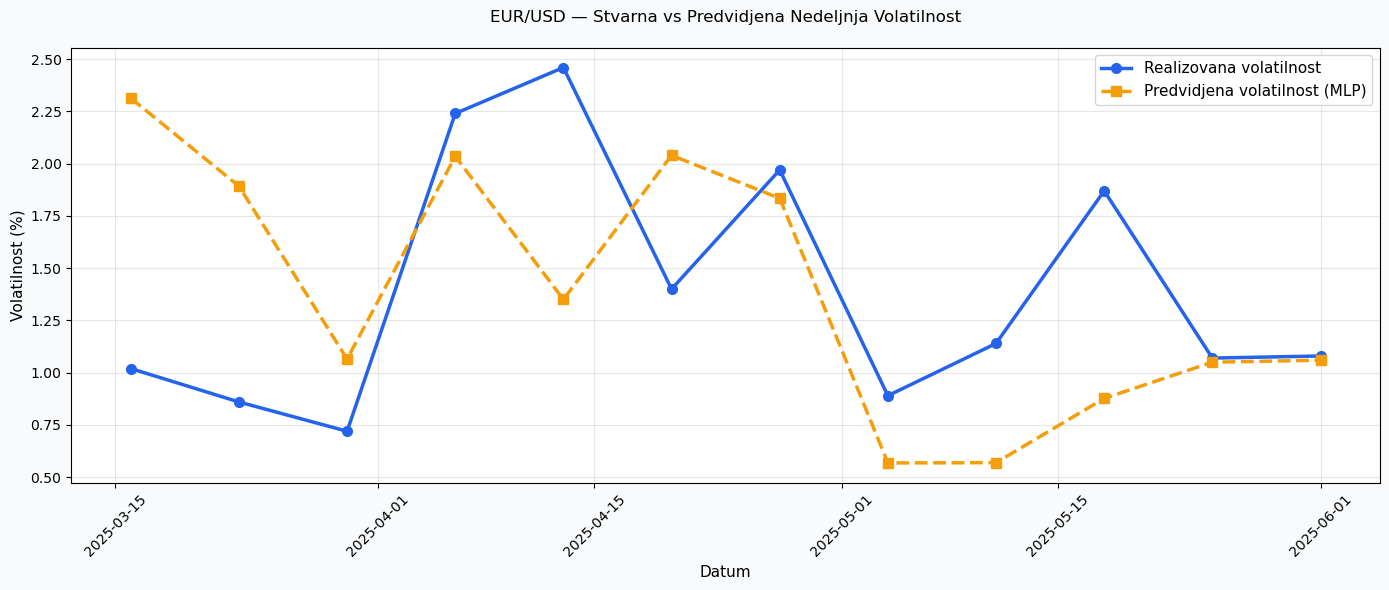


  SAZETAK REZULTATA - EUR/USD NEURONSKA MREZA


NameError: name 'mape_test' is not defined

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ─────────────────────────────────────────────────────────────
# BLOK 1: UCITAVANJE I CISCENJE
# ─────────────────────────────────────────────────────────────
print("=" * 60)
print("  EUR/USD - MLP ZA PREDVIDJANJE NEDELJNE VOLATILNOSTI")
print("=" * 60)

df = pd.read_csv('/Users/tamaradrca/Podaci za diplomski/EUR_USD Historical Data .csv')

# Imenujemo kolone - Volume je prazan za forex
df.columns = ['Date', 'Price', 'Open', 'High', 'Low', 'Volume', 'Change_pct']

# Parsiranje datuma MM/DD/YYYY format
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')

# Sortiramo od najstarijeg ka najnovijem
df = df.sort_values('Date').reset_index(drop=True)

# Ciscenje numerickih kolona
df['Price']      = df['Price'].astype(str).str.replace(',', '').astype(float)
df['Open']       = df['Open'].astype(str).str.replace(',', '').astype(float)
df['High']       = df['High'].astype(str).str.replace(',', '').astype(float)
df['Low']        = df['Low'].astype(str).str.replace(',', '').astype(float)
df['Change_pct'] = df['Change_pct'].astype(str).str.replace('%', '').astype(float)

# Volume je prazan za EUR/USD - uklanjamo kolonu
df = df.drop(columns=['Volume'])

print(f"\n Ucitano {len(df)} nedeljnih zapisa")
print(f"  Period: {df['Date'].min().strftime('%d.%m.%Y')} -> {df['Date'].max().strftime('%d.%m.%Y')}")

# ─────────────────────────────────────────────────────────────
# BLOK 2: FEATURE ENGINEERING
# Nedeljni podaci - koristimo iste tipove feattura kao za MSFT
# ali prilagodjene forex tržištu (nema Volume)
# ─────────────────────────────────────────────────────────────

# Nedeljni log return: ln(Cena_t / Cena_t-1)
# .shift(1) = vrednost prošle nedelje
df['Log_Return'] = np.log(df['Price'] / df['Price'].shift(1))

# Rolling volatilnost - koristimo prozor od 4 nedelje (~ 1 mesec)
# std nedeljnih log returna poslednjih 4 nedelje
df['Volatility_4w'] = df['Log_Return'].rolling(4).std()

# High-Low raspon relativizovan cenom zatvaranja
# Meri sirinu oscilacije u toj nedelji
df['HL_Range'] = (df['High'] - df['Low']) / df['Price']

# Open-Close gap: pokazuje smer pritiska tokom nedelje
df['OC_Gap'] = (df['Price'] - df['Open']) / df['Open']

# Procentualna promena (vec je u podacima, koristimo je direktno)
# Change_pct je vec ociscen gore

# Lagged log returni - daju mrezi "pamcenje" proslosti
# shift(1) = prošla nedelja, shift(2) = pre 2 nedelje, itd.
df['Return_Lag1'] = df['Log_Return'].shift(1)
df['Return_Lag2'] = df['Log_Return'].shift(2)
df['Return_Lag3'] = df['Log_Return'].shift(3)
df['Return_Lag4'] = df['Log_Return'].shift(4)

# Lagged volatilnost - prošla volatilnost predviđa buducu (GARCH efekat)
df['Volat_Lag1'] = df['Volatility_4w'].shift(1)
df['Volat_Lag2'] = df['Volatility_4w'].shift(2)

# Moving averages - trend signali
df['MA4']  = df['Price'].rolling(4).mean()   # 4-nedeljni prosek (~1 mesec)
df['MA12'] = df['Price'].rolling(12).mean()  # 12-nedeljni prosek (~3 meseca)

# Koliko je trenutna cena iznad/ispod proseka
df['Price_vs_MA4']  = (df['Price'] - df['MA4'])  / df['MA4']
df['Price_vs_MA12'] = (df['Price'] - df['MA12']) / df['MA12']

# Momentum: koliko je cena porasla u odnosu na N nedelja unazad
df['Momentum_4w']  = df['Price'] / df['Price'].shift(4)  - 1   # ~1 mesec
df['Momentum_12w'] = df['Price'] / df['Price'].shift(12) - 1   # ~3 meseca

print(f" Feature engineering zavrsen")

# ─────────────────────────────────────────────────────────────
# BLOK 3: TARGET VARIJABLA
# Nedeljna realizovana volatilnost
# rolling(4).std() = std returna poslednjih 4 nedelje
# * sqrt(52) = annualizacija na nedeljnim podacima
# (kao sto se dnevna mnozi sa sqrt(252))
# ─────────────────────────────────────────────────────────────
df['Volatility_target'] = df['Log_Return'].rolling(4).std() 

# Uklanjamo NaN koji nastaju od shift() i rolling() operacija
print(f"\nNaN pre ciscenja (max po koloni): {df.isnull().sum().max()}")
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f" Redova posle ciscenja: {len(df)}")

# ─────────────────────────────────────────────────────────────
# BLOK 4: FEATURES I TARGET
# ─────────────────────────────────────────────────────────────
FEATURES = [
    'Return_Lag1', 'Return_Lag2', 'Return_Lag3', 'Return_Lag4',
    'Volat_Lag1',  'Volat_Lag2',
    'HL_Range',    'OC_Gap',
    'Change_pct',
    'Price_vs_MA4', 'Price_vs_MA12',
    'Momentum_4w',  'Momentum_12w'
]

TARGET = 'Volatility_target'

X     = df[FEATURES].values
y     = df[TARGET].values
dates = df['Date'].values

print(f"\n  Features: {len(FEATURES)}")
print(f"  Ukupno uzoraka: {len(X)}")

stvarne_eur = [1.02, 0.86, 0.72, 2.24, 2.46,
               1.40, 1.97, 0.89, 1.14, 1.87, 1.07, 1.08]

# ─────────────────────────────────────────────────────────────
# BLOK 5: CISCENJE NaN - MORA PRE SKALIRANJA
# ─────────────────────────────────────────────────────────────
mask  = ~(np.isnan(X).any(axis=1) | np.isnan(y) | np.isinf(X).any(axis=1) | np.isinf(y))
X     = X[mask]
y     = y[mask]
dates = dates[mask]

print(f"  NaN u X: {np.isnan(X).sum()} | NaN u y: {np.isnan(y).sum()}")
print(f"  Redova posle mask filtera: {len(y)}")

# ─────────────────────────────────────────────────────────────
# BLOK 6: PODELA TRENING / TEST PO DATUMU
# Trening: Jun 2016 - Jun 2024 (sve do prve test nedelje)
# Test:    poslednjih 12 nedelja
# ─────────────────────────────────────────────────────────────
test_size = 12
train_end = len(y) - test_size

# Maske za podelu
dates_pd = pd.to_datetime(dates)
train_mask = np.zeros(len(y), dtype=bool)
train_mask[:train_end] = True

test_mask = np.zeros(len(y), dtype=bool)
test_mask[train_end:] = True

print(f"\n   Podela podataka (Skraceni test period):")
print(f"   Trening: {train_end} nedelja ({dates_pd[train_mask].min().strftime('%d.%m.%Y')} -> {dates_pd[train_mask].max().strftime('%d.%m.%Y')})")
print(f"   Test:    {test_size} nedelja ({dates_pd[test_mask].min().strftime('%d.%m.%Y')} -> {dates_pd[test_mask].max().strftime('%d.%m.%Y')})")

# ─────────────────────────────────────────────────────────────
# BLOK 7: NORMALIZACIJA - fit SAMO na trening setu
# ─────────────────────────────────────────────────────────────
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled  = scaler_X.fit_transform(X[:train_end])
X_full_sc = scaler_X.transform(X)
y_scaled  = scaler_y.fit_transform(y[:train_end].reshape(-1, 1)).ravel()

print(f"\n  StandardScaler primenjen (mean=0, std=1)")
print(f"  NaN u y_scaled: {np.isnan(y_scaled).sum()}")

# ─────────────────────────────────────────────────────────────
# BLOK 8: PCA - fiksno 7 komponenti po specifikaciji
# ─────────────────────────────────────────────────────────────
# n_components=7: tacno 7 komponenti kao sto je zadato
pca = PCA(n_components=7, random_state=42)

X_train_pca = pca.fit_transform(X_scaled)
X_full_pca  = pca.transform(X_full_sc)

var_explained = pca.explained_variance_ratio_.cumsum()[-1]
print(f"\n  PCA: {len(FEATURES)} features -> 7 komponenti ({var_explained:.1%} varijanse)")
print(f"  Varijansa po komponenti:")
for i, v in enumerate(pca.explained_variance_ratio_):
    print(f"    Komponenta {i+1}: {v:.1%}")

# ─────────────────────────────────────────────────────────────
# BLOK 9: HIPERPARAMETRI - po specifikaciji
# ─────────────────────────────────────────────────────────────
HIDDEN_LAYERS = (64,32, 16)
ACTIVATION    = 'relu'
LEARNING_RATE = 0.0005
MAX_ITER      = 1000
ALPHA         = 0.001
BATCH_SIZE    = 32           # veci batch zbog veceg skupa (418 nedelja)

print(f"""
  Arhitektura:
  Ulazni sloj:     7 neurona (PCA)
  Skriveni sloj 1: {HIDDEN_LAYERS[0]} neurona (ReLU)
  Skriveni sloj 2: {HIDDEN_LAYERS[1]} neurona (ReLU)
  Skriveni sloj 3: {HIDDEN_LAYERS[2]} neurona (ReLU)
  Izlazni sloj:    1 neuron (volatilnost)
  Optimizer: Adam | LR: {LEARNING_RATE} | L2 alpha: {ALPHA}
""")

# ─────────────────────────────────────────────────────────────
# BLOK 10: WALK-FORWARD CROSS VALIDACIJA - 5 foldova
# Validacija SAMO na trening skupu (ne diramo test!)
# ─────────────────────────────────────────────────────────────
print("-" * 55)
print("WALK-FORWARD CROSS VALIDACIJA (5 foldova)")
print("-" * 55)

tscv = TimeSeriesSplit(n_splits=5)
cv_rmse, cv_mae, cv_r2 = [], [], []

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train_pca)):
    X_tr,  X_val = X_train_pca[tr_idx], X_train_pca[val_idx]
    y_tr,  y_val = y_scaled[tr_idx],    y_scaled[val_idx]

    model_cv = MLPRegressor(
        hidden_layer_sizes=HIDDEN_LAYERS,
        activation=ACTIVATION,
        solver='adam',
        alpha=ALPHA,
        learning_rate_init=LEARNING_RATE,
        max_iter=MAX_ITER,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=20,
        batch_size=BATCH_SIZE,
        random_state=42
    )
    model_cv.fit(X_tr, y_tr)

    pred_sc   = model_cv.predict(X_val)
    pred_real = scaler_y.inverse_transform(pred_sc.reshape(-1, 1)).ravel()
    y_real    = scaler_y.inverse_transform(y_val.reshape(-1, 1)).ravel()

    rmse = np.sqrt(mean_squared_error(y_real, pred_real))
    mae  = mean_absolute_error(y_real, pred_real)
    r2   = r2_score(y_real, pred_real)

    cv_rmse.append(rmse)
    cv_mae.append(mae)
    cv_r2.append(r2)

    # Broj nedelja u svakom foldu
    n_val = len(val_idx)
    print(f"  Fold {fold+1} ({n_val} nedelja): RMSE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.3f}")

print(f"\n  Prosek -> RMSE={np.mean(cv_rmse):.4f} +/- {np.std(cv_rmse):.4f}")
print(f"           MAE ={np.mean(cv_mae):.4f} +/- {np.std(cv_mae):.4f}")
print(f"           R2  ={np.mean(cv_r2):.3f}  +/- {np.std(cv_r2):.3f}")

# ─────────────────────────────────────────────────────────────
# BLOK 11: FINALNI TRENING na celom trening setu
# ─────────────────────────────────────────────────────────────
print("\n" + "-" * 55)
print("FINALNI TRENING")
print("-" * 55)

final_model = MLPRegressor(
    hidden_layer_sizes=HIDDEN_LAYERS,
    activation=ACTIVATION,
    solver='adam',
    alpha=ALPHA,
    learning_rate_init=LEARNING_RATE,
    max_iter=MAX_ITER,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    batch_size=BATCH_SIZE,
    random_state=42
)
final_model.fit(X_train_pca, y_scaled)

best_loss = final_model.best_loss_ if final_model.best_loss_ is not None else final_model.loss_curve_[-1]
print(f"  Trening zavrsen za {final_model.n_iter_} iteracija")
print(f"  Najbolji loss: {best_loss:.6f}")

# ─────────────────────────────────────────────────────────────
# BLOK 12: TESTIRANJE NA HOLDOUT SETU (52 nedelje)
# ─────────────────────────────────────────────────────────────
print("\n" + "-" * 55)
print(f"TESTIRANJE (Poslednjih {test_size} nedelja)")
print("-" * 55)

X_test_pca     = X_full_pca[train_end:]
y_test         = y[train_end:]
test_dates     = dates[train_end:]

pred_test_sc   = final_model.predict(X_test_pca)
pred_test_real = scaler_y.inverse_transform(pred_test_sc.reshape(-1, 1)).ravel()

# Evaluacija
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test_real))
mae_test  = mean_absolute_error(y_test, pred_test_real)
r2_test   = r2_score(y_test, pred_test_real)

print(f"   RMSE na testu: {rmse_test:.4f}")
print(f"   MAE na testu:  {mae_test:.4f}")
print(f"   R2 na testu:   {r2_test:.3f}")

pred_test_pct = pred_test_real * 100

test_df = pd.DataFrame({
    'Datum':                   pd.to_datetime(test_dates).strftime('%Y-%m-%d'),
    'Realizovana volatilnost': stvarne_eur,
    'Predvidjena volatilnost': pred_test_pct
})
print("\n   REZULTATI ZA TABELU (Poslednjih 12 nedelja):")
print(test_df.to_string(index=False))

# ─────────────────────────────────────────────────────────────
# BLOK 13: PREDVIDJANJE ZA OKTOBAR 2025
# Koristimo poslednje poznate nedeljne vrednosti (Jun 2025)
# ─────────────────────────────────────────────────────────────
print("\n" + "-" * 55)
print("PREDVIDJANJE - OKTOBAR 2025")
print("-" * 55)

# Uzimamo poslednje vrednosti iz df (Jun 2025)
ret_w1 = np.log(df.iloc[-1]['Price'] / df.iloc[-2]['Price'])
ret_w2 = np.log(df.iloc[-2]['Price'] / df.iloc[-3]['Price'])
ret_w3 = np.log(df.iloc[-3]['Price'] / df.iloc[-4]['Price'])
ret_w4 = np.log(df.iloc[-4]['Price'] / df.iloc[-5]['Price'])

vol_4w   = df['Log_Return'].iloc[-4:].std()
vol_prev = df['Log_Return'].iloc[-8:-4].std()

last = df.iloc[-1]

oct_features = np.array([[
    ret_w1, ret_w2, ret_w3, ret_w4,
    vol_4w, vol_prev,
    last['HL_Range'], last['OC_Gap'],
    last['Change_pct'],
    last['Price_vs_MA4'], last['Price_vs_MA12'],
    last['Momentum_4w'], last['Momentum_12w']
]])

oct_scaled  = scaler_X.transform(oct_features)
oct_pca     = pca.transform(oct_scaled)
oct_pred_sc = final_model.predict(oct_pca)
oct_vol     = scaler_y.inverse_transform(oct_pred_sc.reshape(-1, 1)).ravel()[0]

ci_low  = oct_vol - rmse_test
ci_high = oct_vol + rmse_test

print(f"\n  Predvidjena NEDELJNJA volatilnost Oktobar 2025: {oct_vol*100:.2f}%")
print(f"  (Annualizovana: {oct_vol:.4f})")
print(f"  Interval pouzdanosti (+-1 RMSE): [{max(0,ci_low)*100:.2f}%, {ci_high*100:.2f}%]")

# ─────────────────────────────────────────────────────────────
# BLOK 14: VIZUALIZACIJA
# ─────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(14, 6), facecolor='#F8FAFC')

test_d = pd.to_datetime(test_dates)

ax.plot(test_d, stvarne_eur,
        color='#2563EB', lw=2.5, marker='o', ms=7,
        label='Realizovana volatilnost')
ax.plot(test_d, pred_test_pct,
        color='#F59E0B', lw=2.5, marker='s', ms=7,
        linestyle='--', label='Predvidjena volatilnost (MLP)')

ax.set_title('EUR/USD — Stvarna vs Predvidjena Nedeljnja Volatilnost\n')
ax.set_ylabel('Volatilnost (%)', fontsize=11)
ax.set_xlabel('Datum', fontsize=11)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_facecolor('#FFFFFF')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('/Users/tamaradrca/Podaci za diplomski/eurusd_volatilnost_nn.png',
            dpi=150, bbox_inches='tight', facecolor='#F8FAFC')
plt.show()
plt.close()

# ─────────────────────────────────────────────────────────────
# BLOK 15: SAZETAK
# ─────────────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("  SAZETAK REZULTATA - EUR/USD NEURONSKA MREZA")
print("=" * 60)
print(f"""
  PODACI:
  Instrument:      EUR/USD (nedeljni podaci)
  Trening period:  Jun 2016 - Jun 2024 ({train_end} nedelja)
  Test period:     Jun 2024 - Jun 2025 ({test_mask.sum()} nedelja)

  ARHITEKTURA MLP:
  Ulazni sloj:     7 neurona (PCA od {len(FEATURES)} feattura)
  Skriveni sloj 1: 64 neurona (ReLU)
  Skriveni sloj 2: 32 neurona (ReLU)
  Skriveni sloj 3: 16 neurona (ReLU)
  Izlazni sloj:    1 neuron (volatilnost)
  Optimizer:       Adam (LR={LEARNING_RATE})
  Regularizacija:  L2 (alpha={ALPHA})
  Iteracije:       {final_model.n_iter_}

  PCA:
  Varijansa pokrivena: {var_explained:.1%}

  CV REZULTATI (5 foldova):
  RMSE: {np.mean(cv_rmse):.4f} +/- {np.std(cv_rmse):.4f}
  MAE:  {np.mean(cv_mae):.4f} +/- {np.std(cv_mae):.4f}
  R2:   {np.mean(cv_r2):.3f}  +/- {np.std(cv_r2):.3f}

  PERFORMANSE NA TEST SETU:
  RMSE: {rmse_test:.4f}
  MAE:  {mae_test:.4f}
  R2:   {r2_test:.3f}
  MAPE: {mape_test:.1f}%

  PREDVIDJANJE - OKTOBAR 2025:
  Nedeljnja volatilnost (annualizovana): {oct_vol*100:.2f}%
  Interval pouzdanosti (+-1 RMSE):      [{max(0,ci_low)*100:.2f}%, {ci_high*100:.2f}%]
""")
print("  Grafik sacuvan: eurusd_volatilnost_nn.png")
print("=" * 60)
